https://www.youtube.com/watch?v=0YLZXjMHA-8&list=PLV8yxwGOxvvoNkzPfCx2i8an--Tkt7O8Z&index=3
https://colab.research.google.com/drive/16GBgwYR2ECiXVxA1BoLxYshKczNMeEAQ?usp=sharing#scrollTo=pxmMjZ240wob

In [1]:
import torch
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
G = nx.karate_club_graph()
G

In [3]:
G = nx.karate_club_graph() # Comes from library networkx, no need to download data

num_nodes = G.number_of_nodes()
print("Number of people (nodes):", num_nodes)
print("Number of friendships (edges):", G.number_of_edges())

labels = [0 if G.nodes[i]["club"] == "Mr. Hi" else 1 for i in range(num_nodes)]
labels = torch.tensor(labels)
print("Labels:", labels.tolist())

Number of people (nodes): 34
Number of friendships (edges): 78
Labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


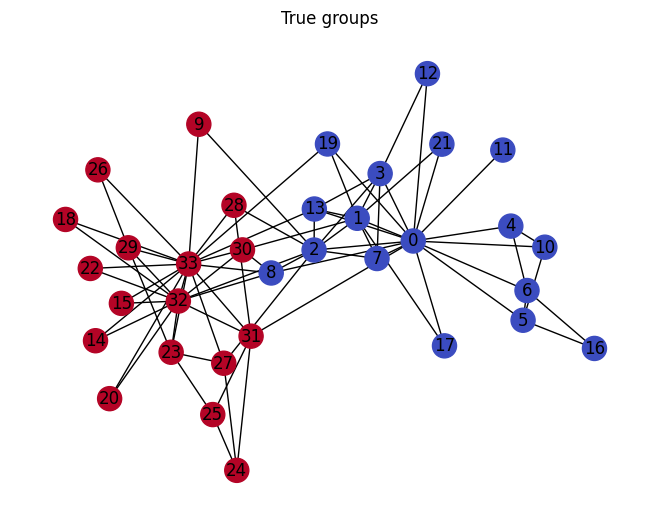

In [4]:
pos = nx.spring_layout(G) 
nx.draw(G, pos, with_labels=True, node_color=labels.tolist(), cmap="coolwarm")
plt.title("True groups")
plt.show()

In [5]:
# pos

In [6]:
print(len(G.edges()), G.edges)
print('-------')
print(len(G.nodes()), G.nodes)
print('---------')
print(G.nodes[9])

78 [(0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 10), (0, 11), (0, 12), (0, 13), (0, 17), (0, 19), (0, 21), (0, 31), (1, 2), (1, 3), (1, 7), (1, 13), (1, 17), (1, 19), (1, 21), (1, 30), (2, 3), (2, 7), (2, 8), (2, 9), (2, 13), (2, 27), (2, 28), (2, 32), (3, 7), (3, 12), (3, 13), (4, 6), (4, 10), (5, 6), (5, 10), (5, 16), (6, 16), (8, 30), (8, 32), (8, 33), (9, 33), (13, 33), (14, 32), (14, 33), (15, 32), (15, 33), (18, 32), (18, 33), (19, 33), (20, 32), (20, 33), (22, 32), (22, 33), (23, 25), (23, 27), (23, 29), (23, 32), (23, 33), (24, 25), (24, 27), (24, 31), (25, 31), (26, 29), (26, 33), (27, 33), (28, 31), (28, 33), (29, 32), (29, 33), (30, 32), (30, 33), (31, 32), (31, 33), (32, 33)]
-------
34 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
---------
{'club': 'Officer'}


In [7]:
# a = np.zeros((34, 34))        
# for i, j in G.edges():        
#     a[i][j] = 1              
#     a[j][i] = 1              
# a

In [8]:
#adjancey matrix
X = torch.eye(num_nodes)
A = torch.tensor(nx.to_numpy_array(G), dtype=torch.float)
A = (A > 0).float() 
A

tensor([[0., 1., 1.,  ..., 1., 0., 0.],
        [1., 0., 1.,  ..., 0., 0., 0.],
        [1., 1., 0.,  ..., 0., 1., 0.],
        ...,
        [1., 0., 0.,  ..., 0., 1., 1.],
        [0., 0., 1.,  ..., 1., 0., 1.],
        [0., 0., 0.,  ..., 1., 1., 0.]])

In [9]:
# nx.to_numpy_array(G)

In [10]:
# torch.equal(torch.tensor(a, dtype=torch.float), A)

In [11]:
A_hat = A + torch.eye(num_nodes)   #Currently no interaction with self, so self-loop needed to create interaction
degree = A_hat.sum(dim=1)     
D_inv_sqrt = torch.diag(degree ** -0.5)   
A_norm = D_inv_sqrt @ A_hat @ D_inv_sqrt   # ABA matrix multiplcation not equal to Asquare X B or BXAsquare
print(D_inv_sqrt.shape, A_hat.shape)
print(A_norm.shape)
A_norm

torch.Size([34, 34]) torch.Size([34, 34])
torch.Size([34, 34])


tensor([[0.0588, 0.0767, 0.0731,  ..., 0.0917, 0.0000, 0.0000],
        [0.0767, 0.1000, 0.0953,  ..., 0.0000, 0.0000, 0.0000],
        [0.0731, 0.0953, 0.0909,  ..., 0.0000, 0.0836, 0.0000],
        ...,
        [0.0917, 0.0000, 0.0000,  ..., 0.1429, 0.1048, 0.0891],
        [0.0000, 0.0000, 0.0836,  ..., 0.1048, 0.0769, 0.0654],
        [0.0000, 0.0000, 0.0000,  ..., 0.0891, 0.0654, 0.0556]])

In [12]:
for i in G.nodes:
    print(i, G.nodes[i])

0 {'club': 'Mr. Hi'}
1 {'club': 'Mr. Hi'}
2 {'club': 'Mr. Hi'}
3 {'club': 'Mr. Hi'}
4 {'club': 'Mr. Hi'}
5 {'club': 'Mr. Hi'}
6 {'club': 'Mr. Hi'}
7 {'club': 'Mr. Hi'}
8 {'club': 'Mr. Hi'}
9 {'club': 'Officer'}
10 {'club': 'Mr. Hi'}
11 {'club': 'Mr. Hi'}
12 {'club': 'Mr. Hi'}
13 {'club': 'Mr. Hi'}
14 {'club': 'Officer'}
15 {'club': 'Officer'}
16 {'club': 'Mr. Hi'}
17 {'club': 'Mr. Hi'}
18 {'club': 'Officer'}
19 {'club': 'Mr. Hi'}
20 {'club': 'Officer'}
21 {'club': 'Mr. Hi'}
22 {'club': 'Officer'}
23 {'club': 'Officer'}
24 {'club': 'Officer'}
25 {'club': 'Officer'}
26 {'club': 'Officer'}
27 {'club': 'Officer'}
28 {'club': 'Officer'}
29 {'club': 'Officer'}
30 {'club': 'Officer'}
31 {'club': 'Officer'}
32 {'club': 'Officer'}
33 {'club': 'Officer'}


In [13]:
class GCNLayer(torch.nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = torch.nn.Linear(in_features, out_features)

    def forward(self, H, A_norm):
        H = A_norm @ H          
        H = self.linear(H)
        return H


class GCN(torch.nn.Module):
    def __init__(self, in_features, hidden, num_classes):
        super().__init__()
        self.layer1 = GCNLayer(in_features, hidden)
        self.layer2 = GCNLayer(hidden, num_classes)

    def forward(self, X, A_norm):
        H = self.layer1(X, A_norm)
        H = torch.relu(H)
        H = self.layer2(H, A_norm)
        return H

model = GCN(in_features=num_nodes, hidden=16, num_classes=2)
print(model)

GCN(
  (layer1): GCNLayer(
    (linear): Linear(in_features=34, out_features=16, bias=True)
  )
  (layer2): GCNLayer(
    (linear): Linear(in_features=16, out_features=2, bias=True)
  )
)


In [14]:
training_nodes = torch.tensor([0, 33])

In [15]:
training_nodes = torch.tensor([15,16,17])
optimizer = torch.optim.Adam(model.parameters(), lr = 0.01)
loss_bce = torch.nn.CrossEntropyLoss()

for epoch in range(100):
    optimizer.zero_grad()
    y = model(X, A_norm)
    loss = loss_bce(y[training_nodes], labels[training_nodes])
    loss.backward()
    optimizer.step()
    print('loss-', loss)

loss- tensor(0.6773, grad_fn=<NllLossBackward0>)
loss- tensor(0.6648, grad_fn=<NllLossBackward0>)
loss- tensor(0.6524, grad_fn=<NllLossBackward0>)
loss- tensor(0.6399, grad_fn=<NllLossBackward0>)
loss- tensor(0.6277, grad_fn=<NllLossBackward0>)
loss- tensor(0.6156, grad_fn=<NllLossBackward0>)
loss- tensor(0.6033, grad_fn=<NllLossBackward0>)
loss- tensor(0.5907, grad_fn=<NllLossBackward0>)
loss- tensor(0.5778, grad_fn=<NllLossBackward0>)
loss- tensor(0.5649, grad_fn=<NllLossBackward0>)
loss- tensor(0.5518, grad_fn=<NllLossBackward0>)
loss- tensor(0.5385, grad_fn=<NllLossBackward0>)
loss- tensor(0.5250, grad_fn=<NllLossBackward0>)
loss- tensor(0.5114, grad_fn=<NllLossBackward0>)
loss- tensor(0.4976, grad_fn=<NllLossBackward0>)
loss- tensor(0.4836, grad_fn=<NllLossBackward0>)
loss- tensor(0.4697, grad_fn=<NllLossBackward0>)
loss- tensor(0.4555, grad_fn=<NllLossBackward0>)
loss- tensor(0.4411, grad_fn=<NllLossBackward0>)
loss- tensor(0.4270, grad_fn=<NllLossBackward0>)
loss- tensor(0.4134,

Accuracy- 0.97


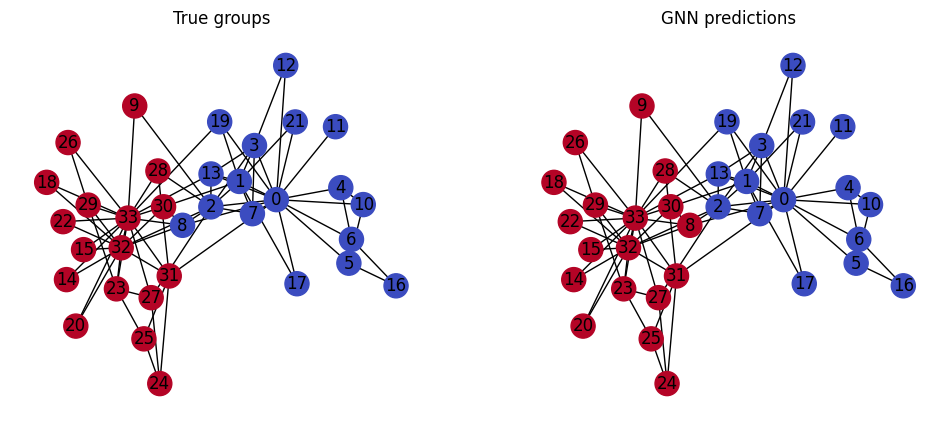

In [16]:
model.eval()
with torch.no_grad():
    pred = model(X, A_norm).argmax(dim=1)

accuracy = (pred == labels).float().mean().item()
print(f"Accuracy-", round(accuracy, 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
nx.draw(G, pos, ax=axes[0], with_labels=True, node_color=labels.tolist(), cmap="coolwarm")
axes[0].set_title("True groups")
nx.draw(G, pos, ax=axes[1], with_labels=True, node_color=pred.tolist(), cmap="coolwarm")
axes[1].set_title("GNN predictions")
plt.show()

In [17]:
pos

{0: array([0.38962065, 0.05633757]),
 1: array([0.20084458, 0.11443686]),
 2: array([0.0555792 , 0.03321677]),
 3: array([0.27807272, 0.22880272]),
 4: array([0.71826005, 0.09445156]),
 5: array([ 0.75951536, -0.14632408]),
 6: array([ 0.77275467, -0.07035879]),
 7: array([0.26750268, 0.01152495]),
 8: array([-0.08879096, -0.02549477]),
 9: array([-0.33265597,  0.35497525]),
 10: array([0.83282143, 0.04050892]),
 11: array([0.69134066, 0.28889707]),
 12: array([0.43740774, 0.48435587]),
 13: array([0.05640896, 0.13816541]),
 14: array([-0.68065836, -0.19872497]),
 15: array([-0.59351778, -0.10316602]),
 16: array([ 1.       , -0.2184582]),
 17: array([ 0.49483487, -0.2118297 ]),
 18: array([-0.78165244,  0.11147536]),
 19: array([0.10065778, 0.30448576]),
 20: array([-0.63311844, -0.34691618]),
 21: array([0.48610397, 0.3040416 ]),
 22: array([-0.69827185, -0.01389437]),
 23: array([-0.4259429 , -0.22820286]),
 24: array([-0.20481853, -0.53025738]),
 25: array([-0.28571111, -0.38762927